# 03 - Storms and observed outages

Retrospective associations using the audited county mapping. The capped hourly-median / >=5% comparisons here are descriptive; notebook 04 defines the approved uncapped future 6/12-hour count targets and >5,000 label. Storm reports and future observation quality are not advance predictors.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import re

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LogNorm
import seaborn as sns

from src import config as C
from src.data import duckdb_path
from src.eda import build_storm_outage_tables, grouped_burden
from src.plotting import BLUE, ORANGE, GREY, CAT, SEQ, fmt_k, heat_axes, use_style

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
use_style()

MIN_TYPE_N, MIN_CELL_N, MIN_STATE_N, MIN_COUNTY_N = 100, 10, 20, 50
CUSTOMER_FACTOR = 1.2
MAJOR = 0.05                        # peak share that counts as a "major" outage
PRE_H, POST_H, MAX_H = 1, 12, 48    # event window: start - 1h ... min(end, start + 48h) + 12h

# DuckDB reads the Parquet files directly: the local copy if there is one, else Hugging Face
# (needs `hf auth login`)
con = duckdb.connect()
OUT = duckdb_path("eaglei/outages_*.parquet")                    # EAGLE-I 15-min outages
STORMS = (ROOT / "data/processed/eda/geography_criteria/storm_event_counties.parquet").as_posix()      # NOAA events mapped to counties
STORM_EVENTS = duckdb_path("storms/storm_events_*.parquet")      # raw NOAA events, before county mapping
CENSUS = duckdb_path("reference/county_census.parquet")

## Timing alignment

EAGLE-I timestamps are UTC. This plot checks alignment with NOAA UTC start times; each point averages available observations, which need not represent the same events at every lag.

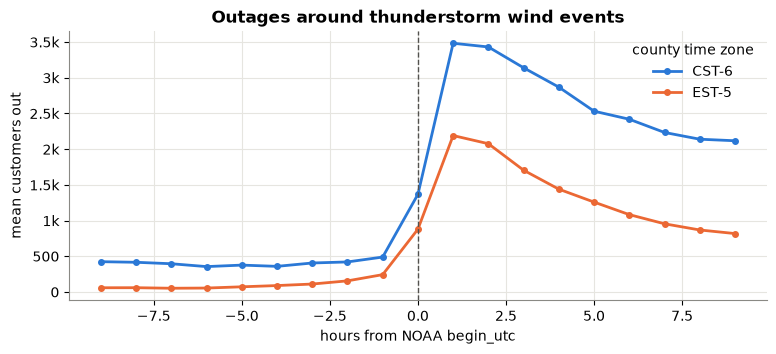

In [2]:
# Mean hourly outage in each county from 9 h before to 9 h after each event's begin_utc hour
tz = con.sql(f'''
with ev as (
  select fips_code, date_trunc('hour', begin_utc) as h0, cz_timezone
  from '{STORMS}'
  where event_type = 'Thunderstorm Wind' and mapped_from = 'county' and year between 2022 and 2024
),
o as (
  select fips_code, date_trunc('hour', run_start_time) as hr, median(customers_out) as out
  from '{OUT}'
  where year(run_start_time) between 2022 and 2024
  group by all
)
select ev.cz_timezone, datediff('hour', ev.h0, o.hr) as lag_h, avg(o.out) as mean_out
from ev
join o on o.fips_code = ev.fips_code
      and o.hr between ev.h0 - interval 9 hour and ev.h0 + interval 9 hour
group by all
order by all
''').df()

fig, ax = plt.subplots(figsize=(9, 3.5))
for (zone, g), color in zip(tz.groupby("cz_timezone"), [BLUE, ORANGE]):
    ax.plot(g["lag_h"], g["mean_out"], marker="o", ms=4, lw=2, color=color, label=zone)
ax.axvline(0, color="#52514e", lw=1, ls="--")
ax.set(xlabel="hours from NOAA begin_utc", ylabel="mean customers out",
       title="Outages around thunderstorm wind events")
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(title="county time zone", frameon=False)
plt.show()

## Join and observation quality

Hourly outages are medians of available readings, capped at the provisional estimate of housing units x 1.2. Windows run from one hour before the start to 12 hours after the end, with event duration capped at 48 hours. Unknown windows retain null outcomes; partial windows can underestimate the peak. The pre-event mean uses available hours only.

In [3]:
build_storm_outage_tables(con, OUT, STORMS, CENSUS, major=MAJOR,
                          pre_h=PRE_H, post_h=POST_H, max_h=MAX_H,
                          customer_factor=CUSTOMER_FACTOR)
imp = con.sql("select * from imp").df()
imp["major"] = imp["major"].astype("boolean")
quality = imp.assign(
    observation_status=np.select(
        [imp["observed_hours"].eq(0), imp["observed_hours"].eq(imp["expected_hours"])],
        ["unknown", "all hours observed"], default="partial"))
print(f"Event-county windows: {len(imp):,}")
display(quality.groupby("observation_status").agg(
    windows=("event_id", "size"), median_observed_fraction=("observed_fraction", "median")))
imp[["peak", "peak_share", "cust_hours", "pre_level", "pre_observed_hours"]].describe().round(2)

Event-county windows: 78,568


,windows,median_observed_fraction
observation_status,,
all hours observed,26895,1.000000
partial,40484,0.714286
unknown,11189,0.000000


,peak,peak_share,cust_hours,pre_level,pre_observed_hours
count,67379.00,67379.00,67379.00,62919.00,78568.00
mean,3432.46,0.05,34541.94,202.08,10.09
std,19424.75,0.11,358499.65,2275.64,8.39
min,0.00,0.00,0.00,0.00,0.00
25%,97.00,0.00,333.50,4.00,2.00
50%,594.00,0.01,2077.50,16.43,9.00
75%,2185.50,0.04,9486.50,76.86,17.00
max,1210689.62,1.00,25137388.12,233808.04,24.00


## Outage severity by event type

Rates use windows with an observed peak, including partial windows. They describe observed severity, not causal effects or validated forecast probabilities. "Major" means an observed peak of at least 5% of estimated customers.

In [4]:
by_type = imp.groupby("event_type").agg(
    rows=("event_id", "size"),
    observed=("peak", "count"),
    median_peak=("peak", "median"),
    median_share=("peak_share", "median"),
    pct_major=("major", "mean"),
    p90_peak=("peak", lambda s: s.quantile(0.9)),
    median_hours_to_peak=("hours_to_peak", "median"),
).sort_values("median_share", ascending=False)
type_burden = grouped_burden(con, ["event_type"]).set_index("event_type")
by_type["total_cust_hours"] = type_burden["cust_hours"]
by_type["unknown"] = by_type["rows"] - by_type["observed"]
by_type["pct_major"] *= 100
by_type["median_share"] *= 100
by_type.round(1)

,rows,observed,median_peak,median_share,pct_major,p90_peak,median_hours_to_peak,total_cust_hours,unknown
event_type,,,,,,,,,
Hurricane (Typhoon),202,202,15445.200195,75.000000,98.5,247946.3,12.5,181402402.9,0
Blizzard,6,5,1514.000000,29.799999,60.0,10563.0,8.0,36514.0,1
Tropical Storm,2007,1973,3064.000000,9.000000,58.9,28238.9,8.0,328964178.3,34
Storm Surge/Tide,182,181,6433.000000,5.800000,54.1,110527.5,8.0,114876743.5,1
Ice Storm,210,157,1474.000000,4.000000,47.8,8050.0,13.0,7629278.0,53
High Wind,804,724,821.500000,2.400000,34.1,9635.5,3.0,22326802.2,80
Tornado,3237,2818,924.200012,2.300000,34.7,10208.8,2.0,57887090.8,419
Strong Wind,1173,1025,1147.000000,2.000000,28.6,8133.5,3.0,18445924.0,148
Thunderstorm Wind,42354,36785,726.000000,1.500000,24.5,6092.0,1.0,161109827.0,5569


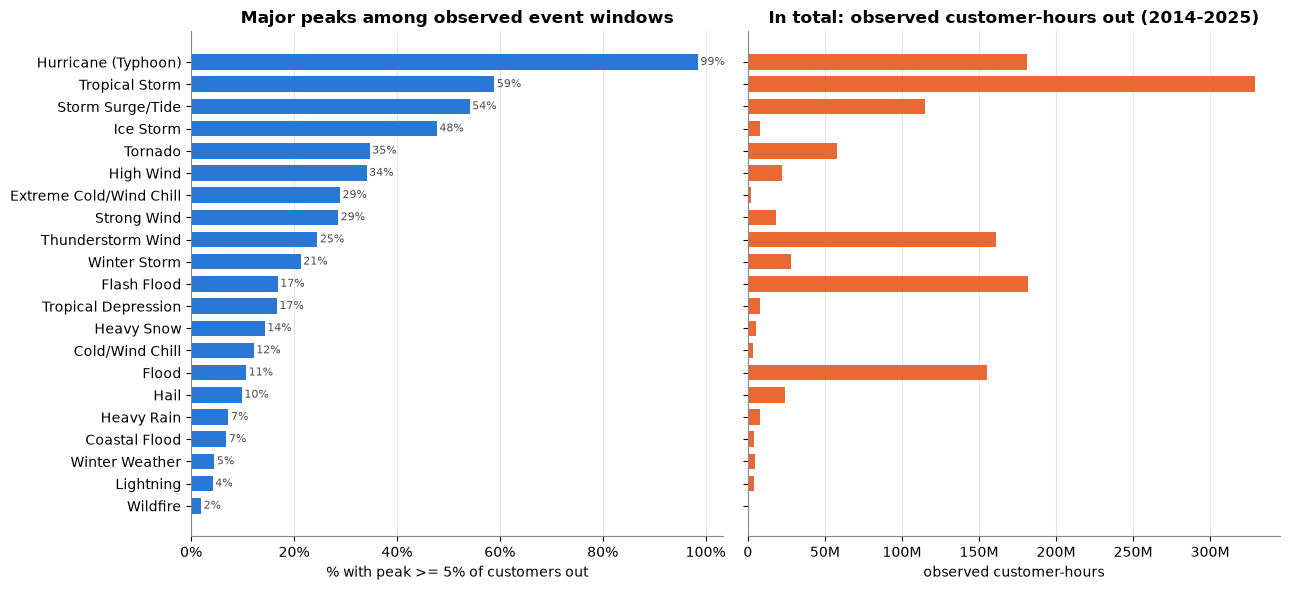

In [5]:
# Keep types with enough rows to say something
common = by_type[by_type["observed"] >= MIN_TYPE_N]
order = common.sort_values("pct_major").index

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
axes[0].barh(order, common.loc[order, "pct_major"], color=BLUE, height=0.7)
axes[0].set(title="Major peaks among observed event windows",
            xlabel=f"% with peak >= {MAJOR:.0%} of customers out")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for y, v in enumerate(common.loc[order, "pct_major"]):
    axes[0].text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=8, color="#52514e")

axes[1].barh(order, common.loc[order, "total_cust_hours"], color=ORANGE, height=0.7)
axes[1].set(title="In total: observed customer-hours out (2014-2025)", xlabel="observed customer-hours")
axes[1].xaxis.set_major_formatter(fmt_k)
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Burden totals count each county-hour once within a type; different types can still share the same outage. Missing hours contribute no measured burden. Positive-only boxplots exclude both observed zeros and unknown windows; the next chart shows those counts separately.

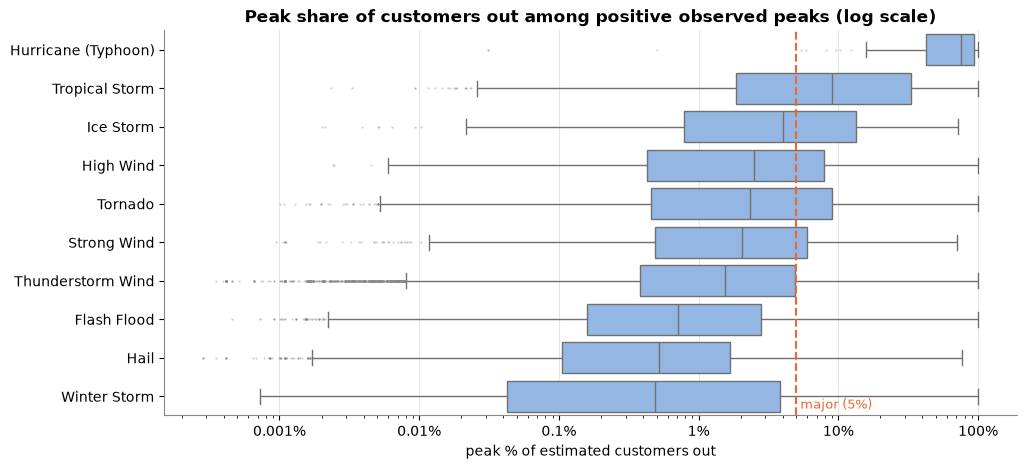

In [6]:
# Peak share distribution for the most common outage-causing types
box_types = ["Hurricane (Typhoon)", "Tropical Storm", "Tornado", "Thunderstorm Wind", "High Wind", "Strong Wind",
             "Flash Flood", "Hail", "Winter Storm", "Ice Storm"]
box = imp[imp["event_type"].isin(box_types) & imp["peak_share"].gt(0)].copy()
box["peak_pct"] = 100 * box["peak_share"]
order = box.groupby("event_type")["peak_pct"].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=box, y="event_type", x="peak_pct", order=order, color="#86b6ef", fliersize=1.5,
            flierprops={"markerfacecolor": "#8a8984", "markeredgecolor": "none", "alpha": 0.4},
            ax=ax, log_scale=True)
ax.axvline(100 * MAJOR, color=ORANGE, lw=1.5, ls="--")
ax.text(100 * MAJOR, len(order) - 0.6, f" major ({MAJOR:.0%})", color=ORANGE, fontsize=9, va="bottom")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}%"))
ax.set(title="Peak share of customers out among positive observed peaks (log scale)",
       xlabel="peak % of estimated customers out", ylabel="")
plt.show()

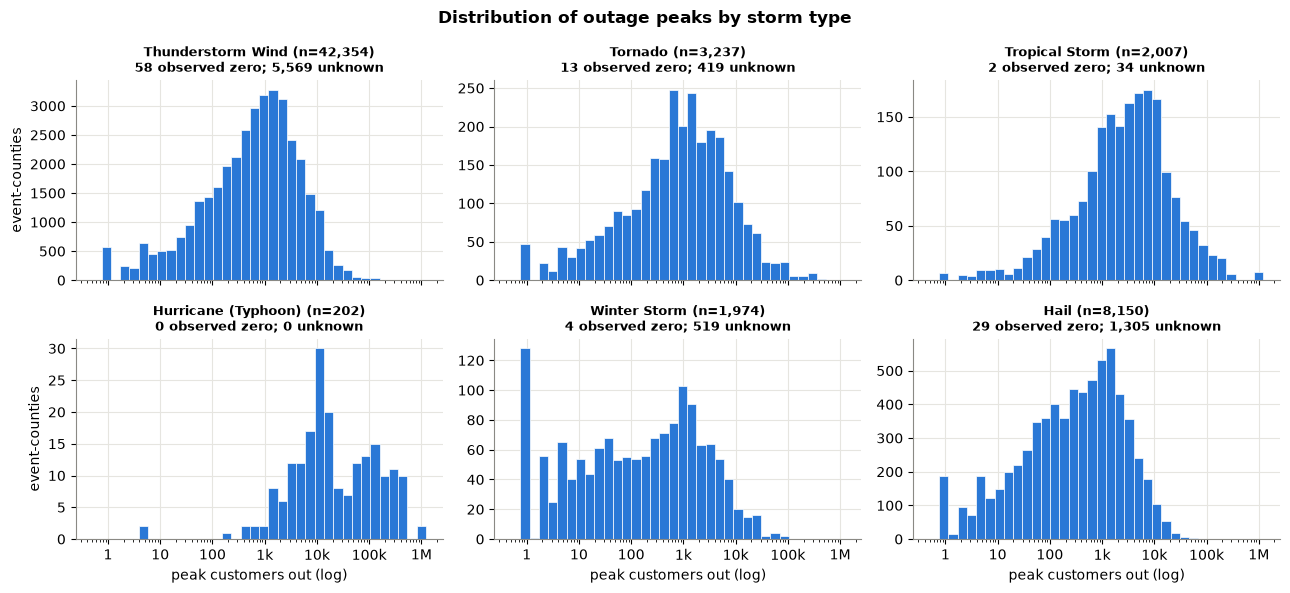

In [7]:
# Histogram of peak customers out: how heavy is the tail for each type?
show = ["Thunderstorm Wind", "Tornado", "Tropical Storm", "Hurricane (Typhoon)", "Winter Storm", "Hail"]
positive_peaks = imp.loc[imp["peak"] > 0, "peak"]
bins = np.geomspace(min(0.5, positive_peaks.min()), positive_peaks.max() * 1.01, 37)
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True)
for ax, ty in zip(axes.flat, show):
    v = imp.loc[imp["event_type"] == ty, "peak"]
    ax.hist(v[v > 0], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_xscale("log")
    ax.set_title(f"{ty} (n={len(v):,})\n{v.eq(0).sum():,} observed zero; {v.isna().sum():,} unknown", fontsize=9)
    ax.xaxis.set_major_formatter(fmt_k)
for ax in axes[1]:
    ax.set_xlabel("peak customers out (log)")
for ax in axes[:, 0]:
    ax.set_ylabel("event-counties")
fig.suptitle("Distribution of outage peaks by storm type", fontweight="bold")
plt.tight_layout()
plt.show()

### Seasonality

Cells with fewer than 10 observed peaks are hidden. Blank cells do not mean zero impact.

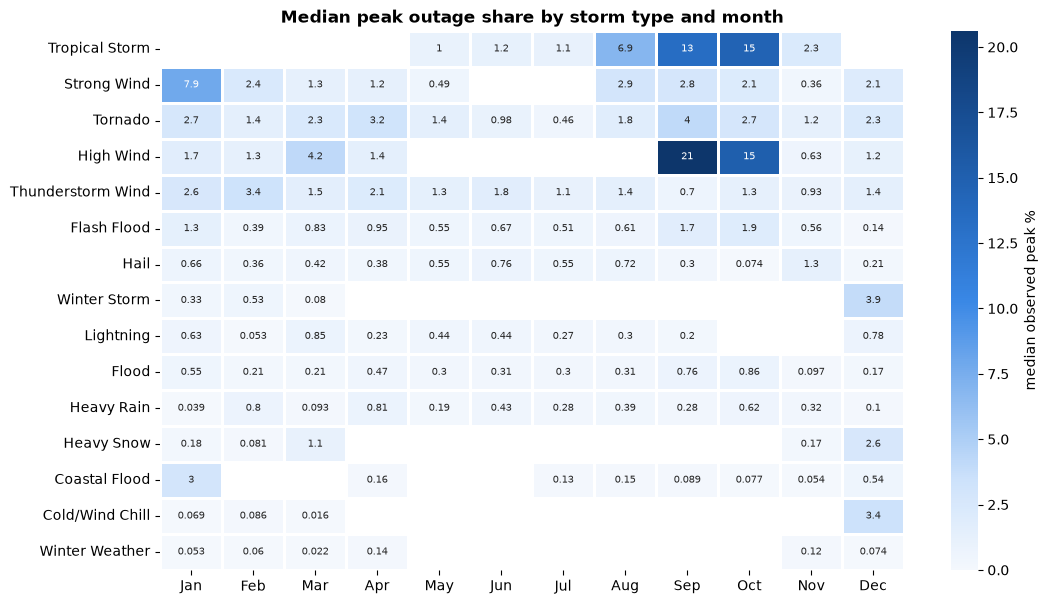

In [8]:
imp["month"] = imp["begin_utc"].dt.month
TYPES_300 = by_type[by_type["observed"] >= 300].index   # types with enough rows for a per-month / per-state grid

cells = imp[imp["event_type"].isin(TYPES_300)].groupby(["event_type", "month"])
grid = (100 * cells["peak_share"].median()).where(cells["peak_share"].count() >= MIN_CELL_N).unstack()
grid = grid.loc[grid.median(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(grid, cmap=SEQ, vmin=0, annot=True, fmt=".2g", annot_kws={"fontsize": 7},
            linewidths=1, linecolor="white", cbar_kws={"label": "median observed peak %"}, ax=ax)
heat_axes(ax)
ax.set(title="Median peak outage share by storm type and month", xlabel="", ylabel="")
plt.show()

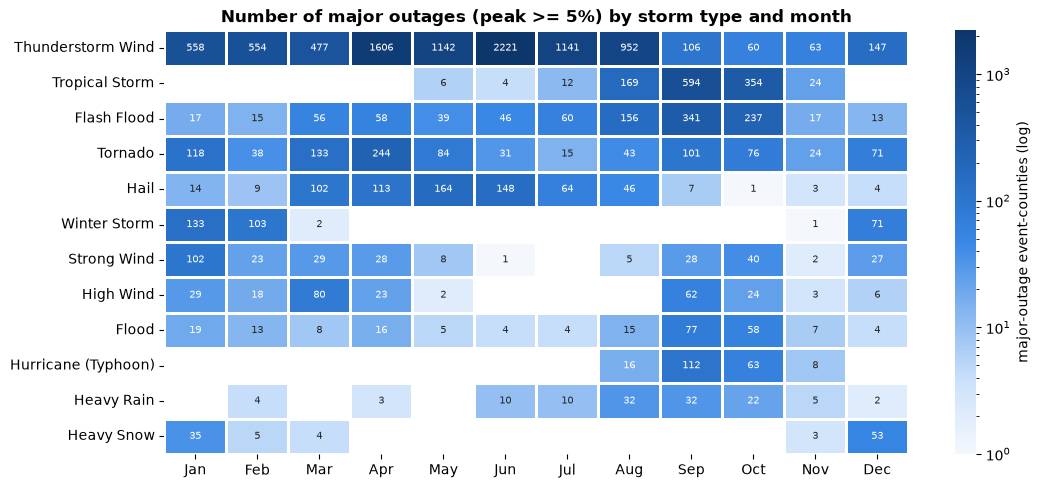

In [9]:
# Count of major outages by type and month: when do the big ones actually happen? (top 12 types)
cnt = imp[imp["major"].fillna(False)].pivot_table(index="event_type", columns="month", values="event_id",
                                    aggfunc="size", fill_value=0)
cnt = cnt.loc[cnt.sum(axis=1).sort_values(ascending=False).index[:12]]

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(cnt.replace(0, np.nan), cmap=SEQ, norm=LogNorm(), annot=cnt, fmt="d", annot_kws={"fontsize": 7},
            linewidths=1, linecolor="white", cbar_kws={"label": "major-outage event-counties (log)"}, ax=ax)
heat_axes(ax)
ax.set(title=f"Number of major outages (peak >= {MAJOR:.0%}) by storm type and month", xlabel="", ylabel="")
plt.show()

### Time to observed peak

Peak timing is restricted to the chosen window; it cannot establish how often the true peak falls outside that window. Ties use the earliest observed hour.

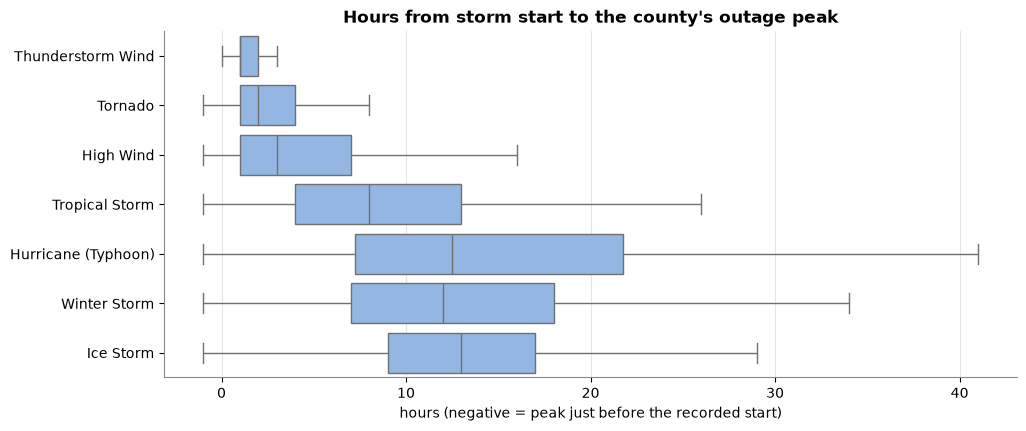

,count,mean,std,min,25%,50%,75%,90%,max
event_type,,,,,,,,,
Thunderstorm Wind,36727.0,2.2,2.5,-1.0,1.0,1.0,2.0,5.0,54.0
Tornado,2805.0,3.2,3.4,-1.0,1.0,2.0,4.0,9.0,13.0
High Wind,718.0,4.5,4.8,-1.0,1.0,3.0,7.0,11.0,24.0
Tropical Storm,1971.0,9.9,8.6,-1.0,4.0,8.0,13.0,21.0,55.0
Hurricane (Typhoon),202.0,14.6,10.0,-1.0,7.2,12.5,21.8,27.0,60.0
Winter Storm,1451.0,13.2,9.1,-1.0,7.0,12.0,18.0,24.0,56.0
Ice Storm,157.0,12.8,5.9,-1.0,9.0,13.0,17.0,21.0,29.0


In [10]:
lag_types = ["Thunderstorm Wind", "Tornado", "High Wind", "Tropical Storm", "Hurricane (Typhoon)",
             "Winter Storm", "Ice Storm"]
lagged = imp[imp["event_type"].isin(lag_types) & (imp["peak"] > 0)]

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.boxplot(data=lagged, x="hours_to_peak", y="event_type", order=lag_types, color="#86b6ef",
            showfliers=False, ax=ax)
ax.set(title="Hours from storm start to the county's outage peak",
       xlabel="hours (negative = peak just before the recorded start)", ylabel="")
plt.show()
lagged.groupby("event_type")["hours_to_peak"].describe(percentiles=[.25, .5, .75, .9]).reindex(lag_types).round(1)

## Regional peaks

Labels identify the candidate episode whose counties contain the largest share of observed outages near each peak. They are associations, not cause assignments. Narrative-derived names are descriptive only and are not used to merge episodes.

In [11]:
# Step 1: region-wide customers out per hour, and the biggest days at least 3 days apart
total = con.sql("select hr, sum(out) as total from hourly group by 1 order by 1").df().set_index("hr")["total"]
daily = total.resample("D").max()

peak_days = []
for day in daily.dropna().sort_values(ascending=False).index:
    if all(abs((day - p).days) >= 3 for p in peak_days):
        peak_days.append(day)
    if len(peak_days) == 40:
        break
peak_hours = [total[d.strftime("%Y-%m-%d")].idxmax() for d in peak_days]   # peak hour within each day

In [12]:
# Step 2: give each NOAA episode a readable label. Storm names come from the episode narrative.
episodes = con.sql(f'''
select episode_id, min(episode_narrative) as narrative,
       string_agg(distinct event_type, ', ' order by event_type) as event_types, min(begin_utc) as begin_utc,
       string_agg(distinct state_abbr, ', ' order by state_abbr) as states
from '{STORMS}'
group by 1
''').df()

TROPICAL = ["Hurricane", "Tropical Storm", "Tropical Depression", "Storm Surge"]
# "<Hurricane|Tropical Storm|...> <Name>" in the narrative; collect every name seen
explicit = episodes["narrative"].str.extract(
    r"\b(?:Hurricane|Tropical Storm|Tropical Depression|Tropical Cyclone|"
    r"Post-Tropical Cyclone|Subtropical Storm|Potential Tropical Cyclone)\s+([A-Z][a-z]+)")[0]
not_names = {"Center", "Wind", "Season", "Warning", "Watch", "One", "Six", "Nine", "Nineteen", "Force"}
names = sorted(set(explicit.dropna()) - not_names)
name_re = re.compile(r"\b(" + "|".join(map(re.escape, names)) + r")\b") if names else re.compile(r"(?!)")


def label(row):
    # Tropical episodes: any known storm name in the narrative. Other episodes (e.g. Matthew's tornadoes in NC):
    # only when the narrative names the storm explicitly ("Hurricane <Name>").
    tropical = any(k in row["event_types"] for k in TROPICAL)
    m = name_re.search(row["narrative"] if isinstance(row["narrative"], str) else "") if tropical else None
    name = m.group(1) if m else (explicit[row.name] if explicit[row.name] in names else None)
    if name:
        return f"{name} ({row['begin_utc']:%b %Y})"
    main_type = row["event_types"].split(", ")[0]
    return f"{main_type}, {row['states']} ({row['begin_utc']:%d %b %Y})"


episodes["storm"] = episodes.apply(label, axis=1)
con.register("eps_df", episodes[["episode_id", "storm"]])
con.sql("create or replace table ev_lab as select ev.*, eps_df.storm from ev join eps_df using (episode_id)")
episodes["storm"].value_counts().head(10)

storm
Helene (Sep 2024)     33
Sally (Sep 2020)      25
Michael (Oct 2018)    23
Debby (Aug 2024)      23
Hermine (Sep 2016)    21
Eta (Nov 2020)        21
Matthew (Oct 2016)    21
Idalia (Aug 2023)     20
Irma (Sep 2017)       20
Ian (Sep 2022)        19
Name: count, dtype: int64

In [13]:
# Find the candidate episode with the most observed outages in its counties at each peak.
# A county counts for a storm if one of its events started within the 5 days before (restoration takes days).
def attribute(hour):
    att = con.sql(f'''
    select e.episode_id, min(e.storm) as storm, sum(h.out) as out_in_storm_counties
    from (select distinct episode_id, storm, fips_code from ev_lab
          where begin_utc between timestamp '{hour}' - interval 5 day and timestamp '{hour}') e
    join hourly h on h.fips_code = e.fips_code and h.hr = timestamp '{hour}'
    group by 1
    order by out_in_storm_counties desc, e.episode_id
    limit 1
    ''').df()
    if att.empty:
        return {"episode_id": None, "storm": "no storm on record", "share_of_total_in_storm_counties": 0.0}
    return {"episode_id": att.at[0, "episode_id"], "storm": att.at[0, "storm"],
            "share_of_total_in_storm_counties": att.at[0, "out_in_storm_counties"] / total[hour]}


top_peaks = pd.DataFrame([{"peak_hour_utc": h, "total_out": total[h], **attribute(h)} for h in peak_hours])
# Keep each candidate episode's highest regional peak.
has_storm = top_peaks["storm"] != "no storm on record"
top_peaks = (pd.concat([top_peaks[has_storm].drop_duplicates("episode_id"), top_peaks[~has_storm]])
             .sort_values("total_out", ascending=False).head(12).reset_index(drop=True))
top_peaks.style.format({"total_out": "{:,.0f}", "share_of_total_in_storm_counties": "{:.0%}"})

,peak_hour_utc,total_out,episode_id,storm,share_of_total_in_storm_counties
0,2017-09-11 14:00:00,"7,967,612",120690.000000,Irma (Sep 2017),41%
1,2024-09-27 15:00:00,"4,270,635",196927.000000,Helene (Sep 2024),18%
2,2024-10-10 14:00:00,"3,432,889",197468.000000,Milton (Oct 2024),65%
3,2022-09-29 12:00:00,"2,500,117",174632.000000,Ian (Sep 2022),65%
4,2016-10-09 02:00:00,"1,924,074",109645.000000,Matthew (Oct 2016),19%
5,2020-10-29 16:00:00,"1,862,051",152629.000000,Zeta (Oct 2020),36%
6,2018-10-11 23:00:00,"1,085,868",131955.000000,Michael (Oct 2018),36%
7,2024-10-03 00:00:00,"1,050,739",196694.000000,Helene (Sep 2024),1%
8,2022-12-24 14:00:00,"970,438",176407.000000,"Cold/Wind Chill, NC (23 Dec 2022)",17%
9,2017-09-17 00:00:00,"904,860",119520.000000,Irma (Sep 2017),1%


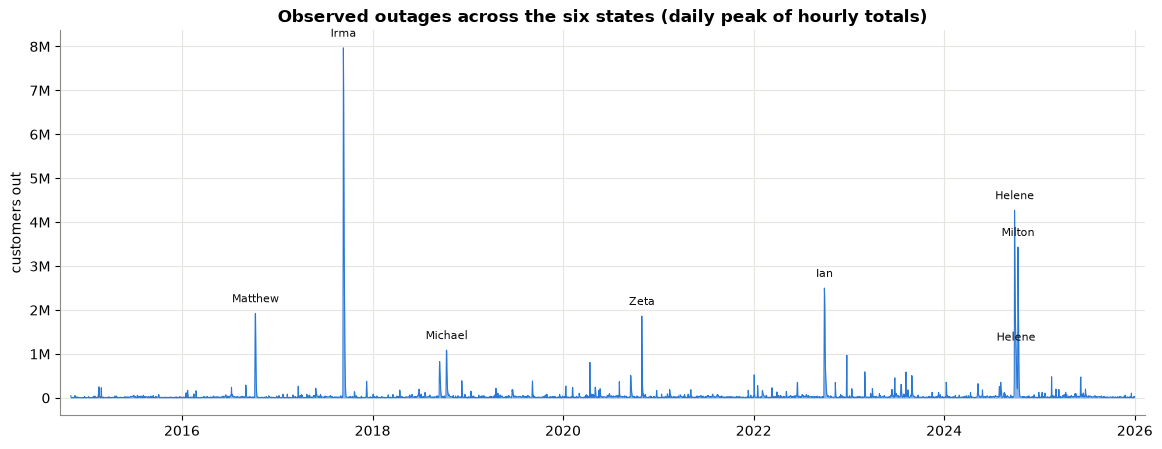

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(daily.index, daily.values, color="#86b6ef", lw=0)
ax.plot(daily.index, daily.values, color=BLUE, lw=0.8)
for _, r in top_peaks.head(8).iterrows():   # label the 8 biggest peaks with the storm name
    ax.annotate(r["storm"].split(" (")[0], (r["peak_hour_utc"], r["total_out"]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=8, color="#0b0b0b")
ax.yaxis.set_major_formatter(fmt_k)
ax.set(title="Observed outages across the six states (daily peak of hourly totals)",
       ylabel="customers out", xlabel="")
ax.margins(x=0.01)
plt.show()

### Monthly observed burden

Totals sum available hourly outage levels. Changing coverage and missing readings limit comparisons between years.

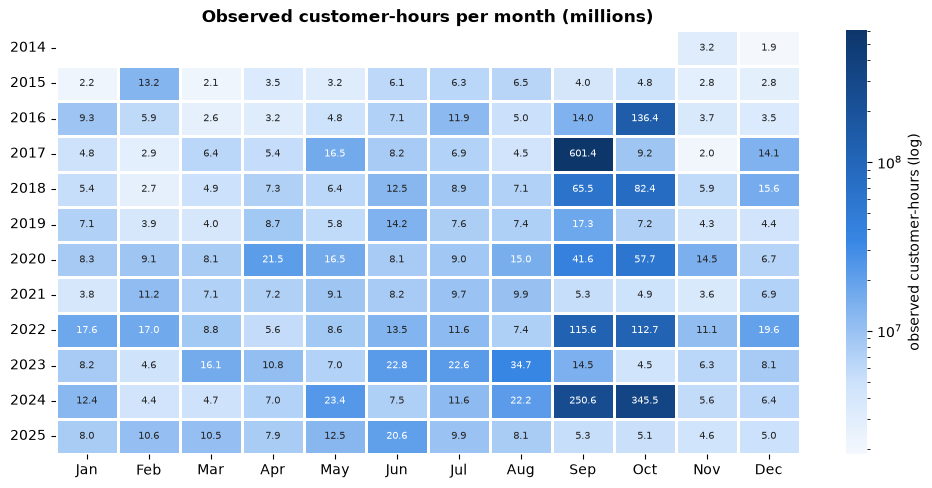

In [15]:
ym = con.sql("select year(hr) as year, month(hr) as month, sum(out) as cust_hours from hourly group by all").df()
grid = ym.pivot(index="year", columns="month", values="cust_hours")

fig, ax = plt.subplots(figsize=(12, 5.5))
sns.heatmap(grid, cmap=SEQ, norm=LogNorm(), linewidths=1, linecolor="white", annot=grid / 1e6, fmt=".1f",
            annot_kws={"fontsize": 7}, cbar_kws={"label": "observed customer-hours (log)"}, ax=ax)
heat_axes(ax)
ax.set(title="Observed customer-hours per month (millions)", xlabel="", ylabel="")
plt.show()

### Local start hour

NOAA local standard time is used here; rates are calculated only among windows with observed peaks.

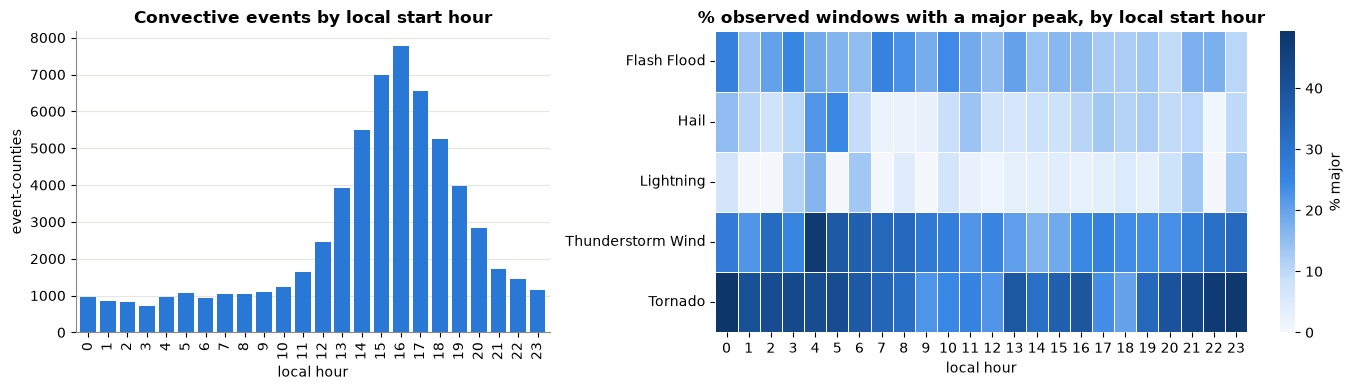

In [16]:
convective = imp[imp["event_type"].isin(["Thunderstorm Wind", "Tornado", "Hail", "Flash Flood", "Lightning"])].copy()
convective["hour"] = convective["begin_local"].dt.hour
pct_by_hour = convective.groupby(["event_type", "hour"])["major"].mean().unstack().astype(float) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 1.4]})
convective.groupby("hour").size().plot.bar(ax=axes[0], color=BLUE, width=0.8)
axes[0].set(title="Convective events by local start hour", xlabel="local hour", ylabel="event-counties")
axes[0].grid(axis="x", visible=False)
sns.heatmap(pct_by_hour, cmap=SEQ, linewidths=0.5, linecolor="white", cbar_kws={"label": "% major"}, ax=axes[1])
axes[1].set(title="% observed windows with a major peak, by local start hour", xlabel="local hour", ylabel="")
heat_axes(axes[1], months=False)
plt.tight_layout()
plt.show()

## State and county comparisons

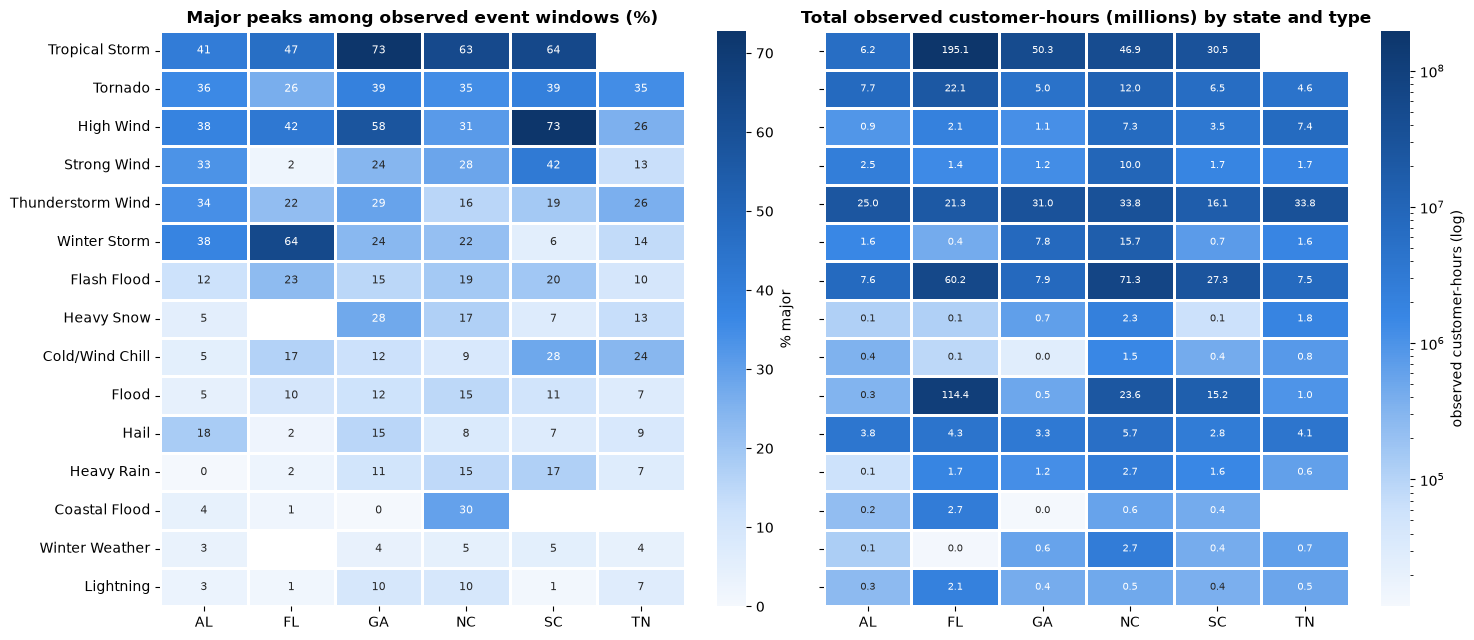

In [17]:
state_events = imp[imp["event_type"].isin(TYPES_300)]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharey=True)

# Left: % major per state and type (blank when fewer than 20 rows), rows ordered by overall % major
pct = state_events.pivot_table(index="event_type", columns="state_abbr", values="major", aggfunc="mean") * 100
n_rows = state_events.pivot_table(index="event_type", columns="state_abbr", values="major", aggfunc="count")
pct = pct.astype(float)
pct = pct.where(n_rows >= MIN_STATE_N).loc[by_type.loc[TYPES_300].sort_values("pct_major", ascending=False).index]
sns.heatmap(pct, cmap=SEQ, annot=True, fmt=".0f", annot_kws={"fontsize": 8}, linewidths=1, linecolor="white",
            cbar_kws={"label": "% major"}, ax=axes[0])
axes[0].set(title="Major peaks among observed event windows (%)", xlabel="", ylabel="")
heat_axes(axes[0], months=False)

# Right: total observed customer-hours per state and type
state_type_burden = grouped_burden(con, ["event_type", "state_abbr"])
ch = state_type_burden.pivot(index="event_type", columns="state_abbr", values="cust_hours").reindex(index=pct.index, columns=pct.columns)
sns.heatmap(ch, cmap=SEQ, norm=LogNorm(), annot=ch / 1e6, fmt=".1f", annot_kws={"fontsize": 7}, linewidths=1,
            linecolor="white", cbar_kws={"label": "observed customer-hours (log)"}, ax=axes[1])
axes[1].set(title="Total observed customer-hours (millions) by state and type", xlabel="", ylabel="")
heat_axes(axes[1], months=False)
plt.tight_layout()
plt.show()

### County rankings

Burden counts each county-hour once. Rates use observed event windows, with at least 50 observed peaks required for ranking.

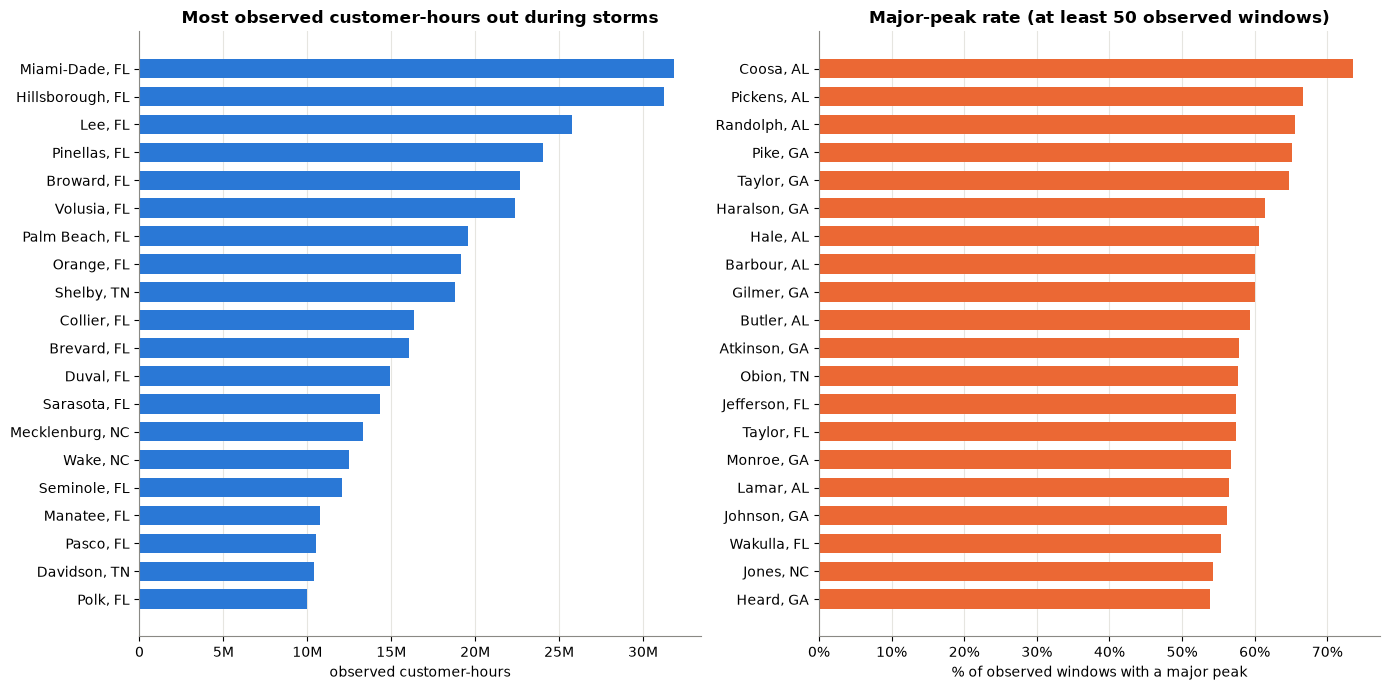

In [18]:
# Storm observed customer-hours per county, counting each county-hour once even if several events cover it
county = con.sql('''
with storm_hours as (
  select distinct fips_code, unnest(generate_series(w0, w1, interval 1 hour)) as hr from ev
)
select c.fips_code, c.county, c.state_name, any_value(c.cust_est) as cust_est, sum(h.out) as storm_cust_hours
from storm_hours s
join hourly h using (fips_code, hr)
join (select * from cust where acs_year = 2023) c using (fips_code)
group by all
''').df()
rate = imp.groupby("fips_code").agg(storm_rows=("peak", "count"), pct_major=("major", "mean"))
county = county.merge(rate, on="fips_code")
county["label"] = county["county"].str.replace(" County", "") + ", " + county["fips_code"].str[:2].map(C.STATES)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
most_hours = county.nlargest(20, "storm_cust_hours").iloc[::-1]
axes[0].barh(most_hours["label"], most_hours["storm_cust_hours"], color=BLUE, height=0.7)
axes[0].set(title="Most observed customer-hours out during storms", xlabel="observed customer-hours")
axes[0].xaxis.set_major_formatter(fmt_k)

most_often = county[county["storm_rows"] >= MIN_COUNTY_N].nlargest(20, "pct_major").iloc[::-1]
axes[1].barh(most_often["label"], 100 * most_often["pct_major"], color=ORANGE, height=0.7)
axes[1].set(title="Major-peak rate (at least 50 observed windows)",
            xlabel="% of observed windows with a major peak")
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [19]:
# Biggest single-county outages, with the storm behind them. One row per county-episode.
worst = (imp.merge(episodes[["episode_id", "storm"]], on="episode_id")
            .sort_values("peak", ascending=False)
            .drop_duplicates(["fips_code", "episode_id"]))
worst = worst.merge(county[["fips_code", "label"]], on="fips_code")
worst[["label", "peak_hr", "event_type", "storm", "peak", "peak_share", "cust_hours"]].head(20) \
    .style.format({"peak": "{:,.0f}", "peak_share": "{:.0%}", "cust_hours": "{:,.0f}"})

,label,peak_hr,event_type,storm,peak,peak_share,cust_hours
0,"Miami-Dade, FL",2017-09-11 14:00:00,Tropical Storm,Irma (Sep 2017),"1,210,690",100%,"25,137,388"
1,"Broward, FL",2017-09-11 14:00:00,Tropical Storm,Irma (Sep 2017),"982,058",100%,"18,547,052"
2,"Palm Beach, FL",2017-09-11 14:00:00,Tropical Storm,Irma (Sep 2017),"814,408",100%,"14,945,325"
3,"Hillsborough, FL",2024-10-10 16:00:00,Hurricane (Typhoon),Milton (Oct 2024),"518,089",68%,"10,675,769"
4,"Lee, FL",2022-09-28 23:00:00,Hurricane (Typhoon),Ian (Sep 2022),"454,451",90%,"5,893,180"
5,"Lee, FL",2017-09-11 14:00:00,Hurricane (Typhoon),Irma (Sep 2017),"451,790",98%,"6,023,534"
6,"Pinellas, FL",2024-10-10 23:00:00,Hurricane (Typhoon),Milton (Oct 2024),"431,742",69%,"10,078,794"
7,"Pinellas, FL",2017-09-12 02:00:00,Hurricane (Typhoon),Irma (Sep 2017),"416,254",68%,"8,220,398"
8,"Orange, FL",2017-09-11 16:00:00,Tropical Storm,Irma (Sep 2017),"330,886",53%,"7,303,638"
9,"Brevard, FL",2017-09-11 14:00:00,Flash Flood,Irma (Sep 2017),"329,522",100%,"3,505,288"


## Episode rankings

Each episode-county contributes one peak; burden integrates the union of its event windows. A sum of county peaks is neither a simultaneous regional peak nor a count of unique customers. Episodes remain separate even when their narrative labels share a storm name.

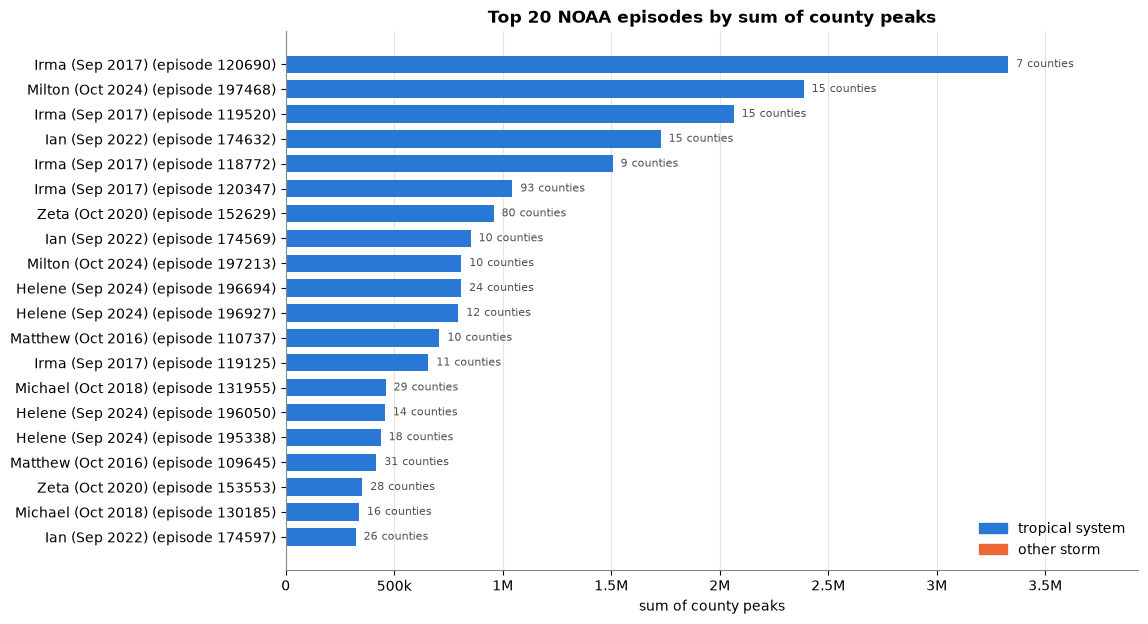

,storm,counties,sum_county_peaks,cust_hours,types
episode_id,,,,,
120690,Irma (Sep 2017),7,"3,329,636","67,195,720","Flood, Hurricane (Typhoon), Storm Surge/Tide, Tornado, Tropical Storm"
197468,Milton (Oct 2024),15,"2,387,313","50,337,070","Flash Flood, Hurricane (Typhoon), Storm Surge/Tide, Tornado, Tropical Storm"
119520,Irma (Sep 2017),15,"2,064,462","62,011,088","Flood, Hurricane (Typhoon), Storm Surge/Tide, Tornado, Tropical Storm"
174632,Ian (Sep 2022),15,"1,727,812","20,972,462","Hurricane (Typhoon), Tropical Storm"
118772,Irma (Sep 2017),9,"1,506,468","27,411,330","Flash Flood, Flood, Storm Surge/Tide, Tornado, Tropical Storm"
120347,Irma (Sep 2017),93,"1,044,390","15,170,512","Flash Flood, Tropical Storm"
152629,Zeta (Oct 2020),80,"957,944","10,429,482","Flash Flood, Tropical Storm"
174569,Ian (Sep 2022),10,"852,080","24,630,243","Flash Flood, Flood, High Surf, Hurricane (Typhoon), Storm Surge/Tide, Tornado, Tropical Storm"
197213,Milton (Oct 2024),10,"809,034","14,977,129","Flash Flood, Flood, Tornado, Tropical Storm"


In [20]:
# Keep NOAA episodes separate; narrative names are labels, not reliable grouping keys.
ep_county = (imp.groupby(["episode_id", "fips_code"], as_index=False)
                .agg(peak=("peak", "max")))
episode_peaks = ep_county.groupby("episode_id").agg(
    counties=("peak", "count"), sum_county_peaks=("peak", lambda s: s.sum(min_count=1)))
episode_burden = grouped_burden(con, ["episode_id"]).set_index("episode_id")
storms = (episode_peaks.join(episode_burden[["cust_hours"]])
          .join(episodes.set_index("episode_id")[["storm", "event_types"]])
          .rename(columns={"event_types": "types"})
          .sort_values("sum_county_peaks", ascending=False))
is_named = storms["storm"].str.match(r"^[A-Z][a-z]+ \(")
storms["kind"] = np.where(is_named | storms["types"].str.contains("Hurricane|Tropical"), "Tropical", "Other")

top20 = storms.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(np.arange(len(top20)), top20["sum_county_peaks"], height=0.7,
        color=[BLUE if k == "Tropical" else ORANGE for k in top20["kind"]])
ax.set_yticks(np.arange(len(top20)), [f"{row.storm} (episode {episode_id})" for episode_id, row in top20.iterrows()])
ax.margins(x=0.18)
for y, (v, c) in enumerate(zip(top20["sum_county_peaks"], top20["counties"])):
    ax.text(v, y, f"  {c} counties", va="center", fontsize=8, color="#52514e")
ax.xaxis.set_major_formatter(fmt_k)
ax.grid(axis="y", visible=False)
ax.set(title="Top 20 NOAA episodes by sum of county peaks", xlabel="sum of county peaks")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["tropical system", "other storm"], frameon=False, loc="lower right")
plt.show()
storms.head(20)[["storm", "counties", "sum_county_peaks", "cust_hours", "types"]] \
    .style.format({"sum_county_peaks": "{:,.0f}", "cust_hours": "{:,.0f}"})

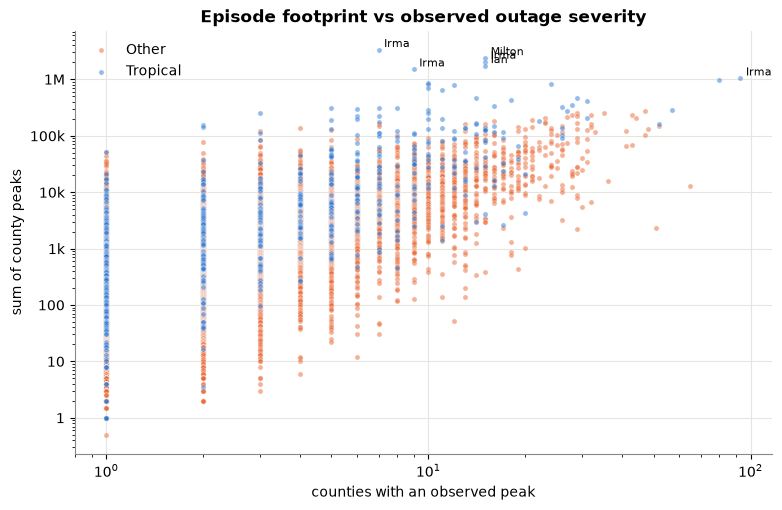

In [21]:
# Bigger storms (more counties) -> more sum of county peaks? Each dot is one storm.
hit = storms[storms["sum_county_peaks"] > 0]
fig, ax = plt.subplots(figsize=(9, 5.5))
for kind, color in [("Other", ORANGE), ("Tropical", BLUE)]:
    k = hit[hit["kind"] == kind]
    ax.scatter(k["counties"], k["sum_county_peaks"], s=14, color=color, alpha=0.5, edgecolor="white",
               linewidth=0.4, label=kind)
for _, r in hit.head(6).iterrows():   # label the 6 biggest
    ax.annotate(r["storm"].split(" (")[0], (r["counties"], r["sum_county_peaks"]), xytext=(4, 2),
                textcoords="offset points", fontsize=8)
ax.set(xscale="log", yscale="log", xlabel="counties with an observed peak", ylabel="sum of county peaks",
       title="Episode footprint vs observed outage severity")
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(frameon=False)
plt.show()

## Reported strength and observed severity

These are retrospective associations. Final magnitude, EF rating, damage and duration require availability checks before use in forecasting; damage and impact narratives must not become advance-prediction features.

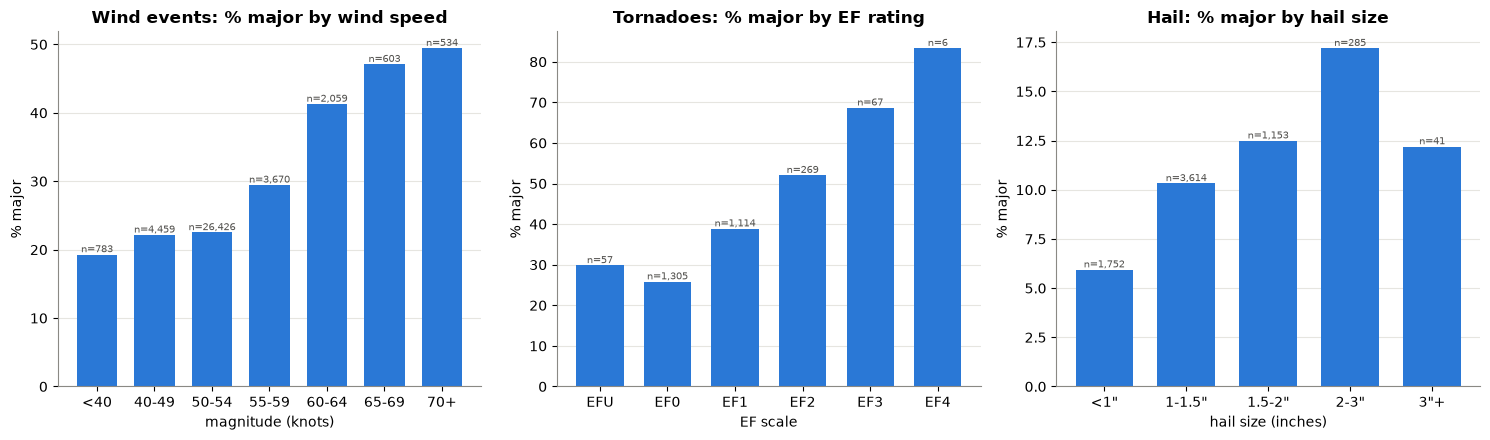

In [22]:
def bar_with_n(ax, rates):
    # Bar of % major per bin, with the bin's row count on top
    ax.bar(rates.index.astype(str), 100 * rates["pct_major"], color=BLUE, width=0.7)
    for x, (v, n) in enumerate(zip(rates["pct_major"], rates["n"])):
        ax.text(x, 100 * v, f"n={int(n):,}", ha="center", va="bottom", fontsize=7, color="#52514e")
    ax.grid(axis="x", visible=False)


fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Wind speed (knots) for wind events; `wind` is reused in the correlation cell below
wind = imp[imp["event_type"].isin(["Thunderstorm Wind", "High Wind", "Strong Wind"]) & imp["magnitude"].notna()].copy()
wind["wind_bin"] = pd.cut(wind["magnitude"], [0, 40, 50, 55, 60, 65, 70, np.inf], right=False,
                          labels=["<40", "40-49", "50-54", "55-59", "60-64", "65-69", "70+"])
bar_with_n(axes[0], wind.groupby("wind_bin", observed=True).agg(pct_major=("major", "mean"), n=("major", "count")))
axes[0].set(title="Wind events: % major by wind speed", xlabel="magnitude (knots)", ylabel="% major")

# EF rating for tornadoes
tornadoes = imp[(imp["event_type"] == "Tornado") & imp["tor_f_scale"].notna()]
bar_with_n(axes[1], tornadoes.groupby("tor_f_scale").agg(pct_major=("major", "mean"), n=("major", "count"))
                        .reindex(["EFU", "EF0", "EF1", "EF2", "EF3", "EF4"]).dropna())
axes[1].set(title="Tornadoes: % major by EF rating", xlabel="EF scale", ylabel="% major")

# Hail size (inches)
hail = imp[(imp["event_type"] == "Hail") & imp["magnitude"].notna()].copy()
hail["hail_bin"] = pd.cut(hail["magnitude"], [0, 1, 1.5, 2, 3, np.inf], right=False,
                          labels=['<1"', '1-1.5"', '1.5-2"', '2-3"', '3"+'])
bar_with_n(axes[2], hail.groupby("hail_bin", observed=True).agg(pct_major=("major", "mean"), n=("major", "count")))
axes[2].set(title="Hail: % major by hail size", xlabel="hail size (inches)", ylabel="% major")

plt.tight_layout()
plt.show()

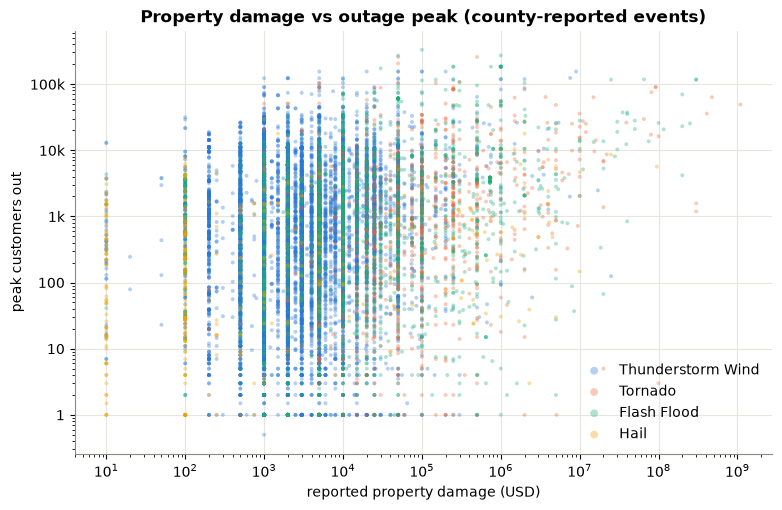

Spearman correlation, damage vs peak share:
                         n  spearman
event_type                          
Tornado             1244.0      0.27
Hail                 367.0      0.27
Flash Flood         2079.0      0.26
Flood                613.0      0.24
Thunderstorm Wind  17153.0      0.10
Lightning            814.0      0.02


In [23]:
# Reported property damage vs outage peak (event-counties with damage > 0)
damage_events = imp[(imp["damage_property_usd"] > 0) & (imp["peak"] > 0)]
damage_events = damage_events[damage_events["mapped_from"] == "county"]   # zone events repeat one damage number across every county in the zone

fig, ax = plt.subplots(figsize=(9, 5.5))
for ty, color in zip(["Thunderstorm Wind", "Tornado", "Flash Flood", "Hail"], CAT):
    k = damage_events[damage_events["event_type"] == ty]
    ax.scatter(k["damage_property_usd"], k["peak"], s=8, alpha=0.35, color=color, edgecolor="none", label=ty)
ax.set(xscale="log", yscale="log", xlabel="reported property damage (USD)", ylabel="peak customers out",
       title="Property damage vs outage peak (county-reported events)")
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(frameon=False, markerscale=2)
plt.show()

print("Spearman correlation, damage vs peak share:")
spearman = damage_events.groupby("event_type").apply(lambda g: pd.Series({
    "n": len(g), "spearman": g["damage_property_usd"].corr(g["peak_share"], method="spearman")}))
print(spearman.query("n >= 100").sort_values("spearman", ascending=False).round(2))

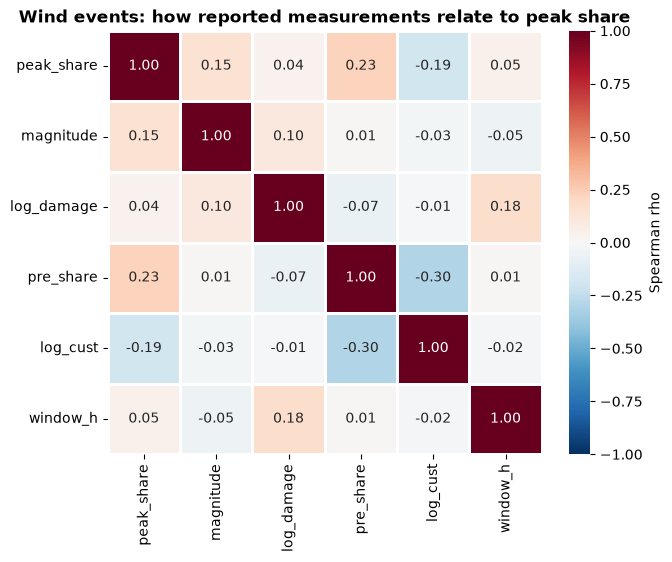

In [24]:
# Numeric features vs peak share in one view (Spearman, wind events from the cell above)
wind["log_damage"] = np.log1p(wind["damage_property_usd"])
wind["pre_share"] = wind["pre_level"] / wind["cust_est"]
wind["log_cust"] = np.log(wind["cust_est"])
wind["window_h"] = (wind["w1"] - wind["w0"]).dt.total_seconds() / 3600 + 1
corr = wind[["peak_share", "magnitude", "log_damage", "pre_share", "log_cust", "window_h"]].corr(method="spearman")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", linewidths=1, linecolor="white",
            cbar_kws={"label": "Spearman rho"}, ax=ax)
ax.set_title("Wind events: how reported measurements relate to peak share")
heat_axes(ax, months=False)
plt.show()

## Outages with a nearby storm record

A qualifying run starts with an observed day at >=5% and >=1,000 customers, following a non-qualifying day or an observation gap. Gaps do not prove a new physical outage. Matches allow one day either side of NOAA events shorter than 10 days. A missing match does not establish a non-weather cause.

In [25]:
outage_onsets = con.sql(f'''
with days as (     -- each county's daily peak
  select fips_code, cast(hr as date) as day, max(out) as peak, max(out / cust_est) as pshare
  from hourly
  group by all
),
flag as (          -- is this day major, and was the day before?
  select *, pshare >= {MAJOR} and peak >= 1000 as is_major,
         lag(pshare >= {MAJOR} and peak >= 1000) over w as prev_major,
         lag(day) over w as prev_day
  from days
  window w as (partition by fips_code order by day)
),
onset as (         -- first day of each run of major days
  select * from flag where is_major and not (coalesce(prev_major, false) and prev_day = day - 1)
),
county_days as (   -- days with a mapped event in the county, +-1 day; skips month-long drought/heat rows
  select distinct fips_code,
         unnest(generate_series(cast(begin_utc as date) - 1, cast(end_utc as date) + 1, interval 1 day))::date as day
  from '{STORMS}'
  where end_utc - begin_utc < interval 10 day
),
state_days as (    -- raw NOAA events, including zone events that never mapped to a county
  select distinct state_fips,
         unnest(generate_series(cast(begin_utc as date) - 1, cast(end_utc as date) + 1, interval 1 day))::date as day
  from '{STORM_EVENTS}'
  where end_utc - begin_utc < interval 10 day
)
select o.fips_code, o.day, o.peak, o.pshare,
       case when outage_onsets.fips_code is not null then 'in the county'
            when sd.state_fips is not null then 'elsewhere in the state only'
            else 'none in the state' end as storm_record
from onset o
left join county_days outage_onsets on outage_onsets.fips_code = o.fips_code and outage_onsets.day = o.day
left join state_days sd on sd.state_fips = left(o.fips_code, 2) and sd.day = o.day
''').df()
outage_onsets["year"] = pd.to_datetime(outage_onsets["day"]).dt.year
outage_onsets["state"] = outage_onsets["fips_code"].str[:2].map(C.STATES)
REC = ["in the county", "elsewhere in the state only", "none in the state"]

print(f"{len(outage_onsets):,} major-outage onsets")
pd.concat({"share of onsets": outage_onsets["storm_record"].value_counts(normalize=True),
           "share of peak customers": outage_onsets.groupby("storm_record")["peak"].sum() / outage_onsets["peak"].sum()}, axis=1) \
    .reindex(REC, fill_value=0).style.format("{:.0%}")

15,521 major-outage onsets


,share of onsets,share of peak customers
storm_record,,
in the county,36%,61%
elsewhere in the state only,47%,28%
none in the state,17%,10%


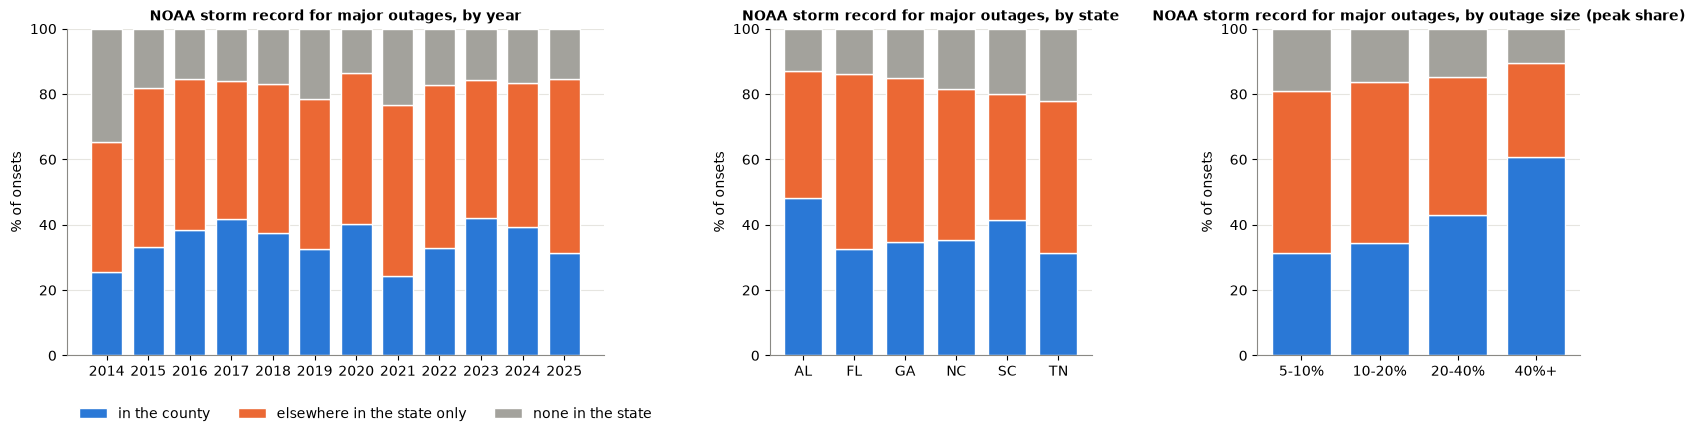

In [26]:
outage_onsets["size_bin"] = pd.cut(outage_onsets["pshare"], [0.05, 0.10, 0.20, 0.40, 1.01], right=False,
                        labels=["5-10%", "10-20%", "20-40%", "40%+"])

# Stacked bars: share of onsets in each storm-record group, by year / state / outage size
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [2, 1.2, 1.2]})
for ax, col, title in zip(axes, ["year", "state", "size_bin"], ["by year", "by state", "by outage size (peak share)"]):
    shares = pd.crosstab(outage_onsets[col], outage_onsets["storm_record"], normalize="index").reindex(columns=REC, fill_value=0) * 100
    bottom = np.zeros(len(shares))
    for rec, color in zip(REC, [BLUE, ORANGE, GREY]):
        ax.bar(shares.index.astype(str), shares[rec], bottom=bottom, color=color, width=0.75,
               edgecolor="white", linewidth=1, label=rec)
        bottom += shares[rec].values
    ax.set(title=f"NOAA storm record for major outages, {title}", ylabel="% of onsets", ylim=(0, 100))
    ax.title.set_fontsize(10)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.tight_layout()
plt.show()

In [27]:
# Largest observed peaks without a matched county storm; the cause remains unknown.
miss = outage_onsets[outage_onsets["storm_record"] != "in the county"].nlargest(15, "peak")
miss = miss.merge(county[["fips_code", "label"]], on="fips_code", how="left")
miss[["label", "day", "peak", "pshare", "storm_record"]].style.format({"peak": "{:,.0f}", "pshare": "{:.0%}"})

,label,day,peak,pshare,storm_record
0,"Charleston, SC",2019-09-05 00:00:00,"135,815",60%,elsewhere in the state only
1,"Chatham, GA",2024-09-27 00:00:00,"118,652",72%,elsewhere in the state only
2,"Pinellas, FL",2024-09-26 00:00:00,"88,670",14%,elsewhere in the state only
3,"Miami-Dade, FL",2025-05-20 00:00:00,"76,064",6%,elsewhere in the state only
4,"St. Johns, FL",2016-10-07 00:00:00,"74,974",64%,elsewhere in the state only
5,"Escambia, FL",2024-08-21 00:00:00,"71,216",40%,elsewhere in the state only
6,"Greenville, SC",2020-10-29 00:00:00,"71,008",28%,elsewhere in the state only
7,"DeKalb, GA",2023-06-25 00:00:00,"65,906",17%,elsewhere in the state only
8,"Greenville, SC",2018-12-09 00:00:00,"59,202",24%,elsewhere in the state only
9,"Hamilton, TN",2025-06-13 00:00:00,"57,278",28%,elsewhere in the state only
